<a id="1"></a>
# <p style="padding:10px;background-color:#CADCFC;margin:0;color:#00246B;font-family:newtimeroman;font-size:150%;text-align:center;overflow:hidden;font-weight:500">Import Libraries</p>

## Install Libraries

Uncomment the line below and run it if you're installing the required libraries for the first time

In [4]:
#!pip install pandas numpy matplotlib seaborn scikit-learn imbalanced-learn

## Import Libraries

In [6]:
# ===============================
# Importing Required Libraries
# ===============================

# Data handling and analysis
import pandas as pd       # For working with data in DataFrame format
import numpy as np        # For numerical operations

# Data visualization
import matplotlib.pyplot as plt  # For creating basic plots
import seaborn as sns            # For more advanced and beautiful plots

# ===============================
# Scikit-learn: Preprocessing, Model Selection & Evaluation
# ===============================

from sklearn.model_selection import train_test_split  # To split data into training and testing sets
from sklearn.metrics import (                         # For evaluating model performance
    accuracy_score, precision_score, recall_score, 
    f1_score, fbeta_score, roc_auc_score, roc_curve, auc, classification_report, ConfusionMatrixDisplay
)

# Preprocessing
from sklearn.preprocessing import StandardScaler       # To scale numerical features
from sklearn.preprocessing import OneHotEncoder        # To encode categorical features
from sklearn.compose import ColumnTransformer          # To apply transformers to specific columns
from sklearn.pipeline import Pipeline                  # To create a pipeline of preprocessing and model

# ===============================
# Machine Learning Classifiers
# ===============================

from sklearn.ensemble import RandomForestClassifier     # Random Forest
from sklearn.tree import DecisionTreeClassifier         # Decision Tree
from sklearn.neighbors import KNeighborsClassifier      # K-Nearest Neighbors
from sklearn.svm import SVC                             # Support Vector Classifier
from sklearn.neural_network import MLPClassifier        # Multi-layer Perceptron (Neural Network)

# ===============================
# Handling Imbalanced Datasets
# ===============================

from imblearn.over_sampling import SMOTE                # SMOTE for oversampling minority class

# ===============================
# General Settings
# ===============================

from time import time  # To measure training time

# Suppress warnings for cleaner output
import warnings
warnings.filterwarnings('ignore')  

# Set plot style to 'ggplot'
plt.style.use('ggplot')

# Show plots directly in the Jupyter notebook
%matplotlib inline

<a id="1"></a>
# <p style="padding:10px;background-color:#CADCFC;margin:0;color:#00246B;font-family:newtimeroman;font-size:150%;text-align:center;overflow:hidden;font-weight:500">Data Initialization</p>

## Input DataSet
DataSet links : "https://www.openml.org/search?type=data&status=active&id=43672&sort=runs"

In [9]:
# Load dataset
df = pd.read_csv('Heart_Disease_Prediction.csv')

# Preview data nicely
print("\n🔎 Preview of the Dataset:")
display(df)


🔎 Preview of the Dataset:


,age,sex,chest_pain_type,resting_bp_s,cholesterol,fasting_blood_sugar,resting_ecg,max_heart_rate,exercise_angina,oldpeak,ST_slope,target
0,40,1,2,140,289,0,0,172,0,0.0,1,0
1,49,0,3,160,180,0,0,156,0,1.0,2,1
2,37,1,2,130,283,0,1,98,0,0.0,1,0
3,48,0,4,138,214,0,0,108,1,1.5,2,1
4,54,1,3,150,195,0,0,122,0,0.0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...
1185,45,1,1,110,264,0,0,132,0,1.2,2,1
1186,68,1,4,144,193,1,0,141,0,3.4,2,1
1187,57,1,4,130,131,0,0,115,1,1.2,2,1
1188,57,0,2,130,236,0,2,174,0,0.0,2,1


<a id="1"></a>
# <p style="padding:10px;background-color:#CADCFC;margin:0;color:#00246B;font-family:newtimeroman;font-size:150%;text-align:center;overflow:hidden;font-weight:500">Data Understanding</p>

In this section, we perform an initial exploration of the dataset to understand its structure, identify any issues, and prepare it for analysis or modeling. 

## Check Number of Records

In [12]:
# Get the number of rows and columns in the DataFrame
rows, columns = df.shape

# Create a DataFrame to display the information
shape_df = pd.DataFrame({
    'Description': ['Number of Rows', 'Number of Columns'],
    'Count': [rows, columns]
})

# Display without index
display(shape_df.style.hide(axis='index'))  # For pandas 1.4+

Description,Count
Number of Rows,1190
Number of Columns,12


## Check Data Types and Missing Values

In [14]:
# ===============================
# Checking for Missing Values
# ===============================

# Calculate the number of missing values in each column
missing = df.isnull().sum()

# Check if there are any missing values and display the result
if missing.any():
    print("⚠️ Missing values per column:\n", missing[missing > 0])
else:
    print("✅ No missing values found.\n")

# ===============================
# Displaying Column Data Types
# ===============================

# Show the data type of each column in the DataFrame
print("🔍 Column data types:\n")
display(df.dtypes.to_frame(name='Data Type'))  # Display as a DataFrame

✅ No missing values found.

🔍 Column data types:



,Data Type
age,int64
sex,int64
chest_pain_type,int64
resting_bp_s,int64
cholesterol,int64
fasting_blood_sugar,int64
resting_ecg,int64
max_heart_rate,int64
exercise_angina,int64
oldpeak,float64


## Check Null Data

In [16]:
df.isnull().sum()

age                    0
sex                    0
chest_pain_type        0
resting_bp_s           0
cholesterol            0
fasting_blood_sugar    0
resting_ecg            0
max_heart_rate         0
exercise_angina        0
oldpeak                0
ST_slope               0
target                 0
dtype: int64

## Check and Remove Duplicate Data

In [18]:
df[df.duplicated()]

,age,sex,chest_pain_type,resting_bp_s,cholesterol,fasting_blood_sugar,resting_ecg,max_heart_rate,exercise_angina,oldpeak,ST_slope,target
163,49,0,2,110,208,0,0,160,0,0.0,1,0
604,58,1,3,150,219,0,1,118,1,0.0,2,1
887,63,1,1,145,233,1,2,150,0,2.3,3,0
888,67,1,4,160,286,0,2,108,1,1.5,2,1
889,67,1,4,120,229,0,2,129,1,2.6,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...
1156,42,1,3,130,180,0,0,150,0,0.0,1,0
1157,61,1,4,140,207,0,2,138,1,1.9,1,1
1158,66,1,4,160,228,0,2,138,0,2.3,1,0
1159,46,1,4,140,311,0,0,120,1,1.8,2,1


In [19]:
# Get the number of duplicate rows in the DataFrame
num_duplicates = df.duplicated().sum()

# Display the number of duplicate rows
print(f"Number of duplicate rows: {num_duplicates}")

Number of duplicate rows: 272


In [20]:
# Store the original number of rows before dropping duplicates
original_rows = df.shape[0]

# Drop duplicate rows from the DataFrame
df = df.drop_duplicates()

# Get the current number of rows and columns after removing duplicates
rows, columns = df.shape

# Calculate the number of duplicates removed
duplicates_removed = original_rows - rows

# Print the new shape, and the number of duplicates removed
print(f"✅ {duplicates_removed} duplicate rows removed. New shape: {df.shape}")

✅ 272 duplicate rows removed. New shape: (918, 12)


## Target Class Distribution

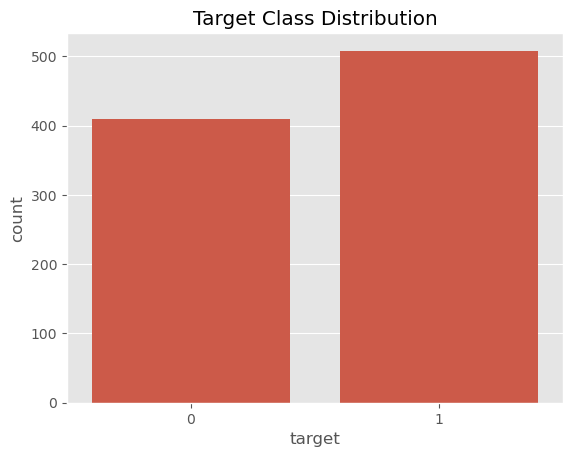

In [22]:
# Create a countplot to visualize the distribution of the target class
# 'x' specifies the target column to plot, 'data=df' indicates the dataset
sns.countplot(x='target', data=df)

# Set the title for the plot to indicate it's showing the target class distribution
plt.title("Target Class Distribution")

# Display the plot
plt.show()

## Feature Correlation (Heatmap)

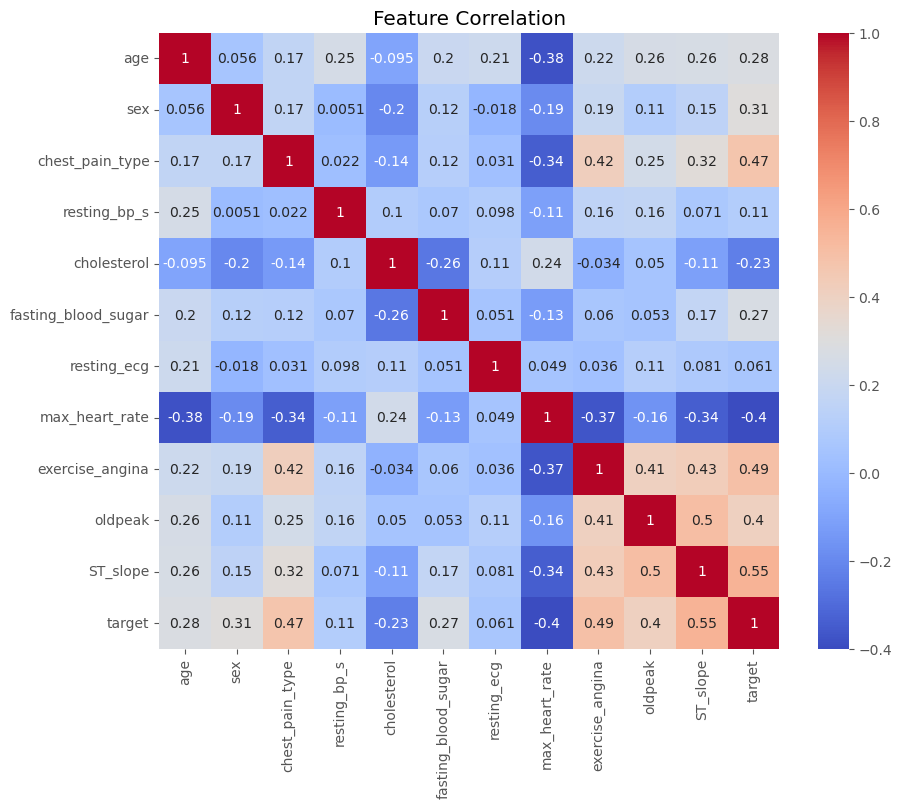

In [24]:
# Set the figure size for the heatmap
plt.figure(figsize=(10, 8))

# Create a heatmap to visualize the correlation between features
# df.corr() computes the correlation matrix, annot=True adds the correlation values to each cell
# cmap='coolwarm' defines the color scheme
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')

# Set the title for the heatmap
plt.title("Feature Correlation")

# Display the heatmap
plt.show()

<a id="1"></a>
# <p style="padding:10px;background-color:#CADCFC;margin:0;color:#00246B;font-family:newtimeroman;font-size:150%;text-align:center;overflow:hidden;font-weight:500">Feature Selection & Data Splitting</p>

In this section, we select relevant features for the model and split the dataset into training and testing sets using stratified sampling to preserve class distribution.

## Define the selected features
these are the columns that will be used in training

In [28]:
selected_features = [
    'age', 'sex', 'chest_pain_type', 'resting_bp_s', 'cholesterol',
    'fasting_blood_sugar', 'max_heart_rate', 'exercise_angina', 'oldpeak', 'ST_slope'
]

## Select the features (X) and the target variable (y)

In [30]:
X = df[selected_features]  # X will contain the selected features
y = df['target']  # y will contain the target variable, which is the heart disease diagnosis (1 = disease, 0 = no disease)

## Identify categorical and numerical columns

In [32]:
# Categorical columns represent discrete categories or labels (not continuous numbers)
categorical_cols = ['sex', 'chest_pain_type', 'fasting_blood_sugar', 'exercise_angina', 'ST_slope']

# Numerical columns represent continuous variables that have meaningful arithmetic relationships (e.g., age, cholesterol)
numerical_cols = list(set(X.columns) - set(categorical_cols))

# Convert categorical columns to 'category' dtype in pandas
# This helps optimize memory usage and makes it easier to apply categorical encoding later
X[categorical_cols] = X[categorical_cols].astype('category')

## Train-test split:
Split the dataset into training and testing sets <br>
- 80% of data will be used for training and 20% for testing (test_size=0.2) <br>
- stratify=y ensures that the distribution of the target variable in both train and test sets is similar

In [34]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

After this step, we will have: <br>
- X_train: Training features (80% of X) <br>
- X_test: Testing features (20% of X) <br>
- y_train: Training target (80% of y) <br>
- y_test: Testing target (20% of y)

<a id="1"></a>
# <p style="padding:10px;background-color:#CADCFC;margin:0;color:#00246B;font-family:newtimeroman;font-size:150%;text-align:center;overflow:hidden;font-weight:500">Data Preprocessing & Handling Imbalance with SMOTE</p>

This step involves standardizing numerical features, encoding categorical ones using one-hot encoding, and applying SMOTE to address class imbalance in the training data.

## Preprocessing step
- Apply different transformations to numerical and categorical columns using ColumnTransformer.<br>
- Numerical columns will be scaled using StandardScaler (standardization to mean=0, std=1).<br>
- Categorical columns will be one-hot encoded (converted into binary vectors).

In [39]:
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), numerical_cols),  # Standard scaling for numerical columns
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)  # OneHot encoding for categorical columns
])

Fit the preprocessor on the training data and transform both the training and test data <br>
- X_train is scaled and encoded based on the column transformations <br>
- X_test is transformed using the fitted preprocessor (no fitting on test set to avoid data leakage) 

In [41]:
X_train_prep = preprocessor.fit_transform(X_train)  # Apply fit and transform on the training data
X_test_prep = preprocessor.transform(X_test)  # Apply transform only on the test data

## Apply SMOTE 
- Synthetic Minority Over-sampling Technique to handle class imbalance in the training set <br>
- SMOTE generates synthetic samples for the minority class (target=1) to balance the class distribution

In [43]:
smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train_prep, y_train)  # Apply SMOTE to the preprocessed training data

<a id="1"></a>
# <p style="padding:10px;background-color:#CADCFC;margin:0;color:#00246B;font-family:newtimeroman;font-size:150%;text-align:center;overflow:hidden;font-weight:500">Train & Evaluate Model Performance</p>

In this section, we train three different classification models using the preprocessed and SMOTE-resampled training data:
- Random Forest
- Support Vector Machine (SVM)
- Artificial Neural Network (ANN)

In [46]:
# Define the models you want to train
models = {
    'Random Forest': RandomForestClassifier(random_state=42),
    'SVM': SVC(probability=True, random_state=42),
    'ANN': MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=500, random_state=42)
}

# Dictionary to store the trained models
trained_models = {}

# Iterate through each model and train it
for name, model in models.items():
    print(f"Training the {name} model...")  # Notify which model is being trained

    # Start measuring the time for model training
    start_time = time()

    # Fit the model on the resampled training data
    model.fit(X_train_res, y_train_res)

    # Calculate the training time
    training_time = time() - start_time

    # Store the trained model in the dictionary
    trained_models[name] = model

    # Print the completion message and training time
    print(f"{name} model trained in {training_time:.4f} seconds.\n")
    
# Final print message after all models are trained
print("All models have been trained successfully!")

Training the Random Forest model...
Random Forest model trained in 0.2417 seconds.

Training the SVM model...
SVM model trained in 0.0785 seconds.

Training the ANN model...
ANN model trained in 3.0710 seconds.

All models have been trained successfully!


<a id="1"></a>
# <p style="padding:10px;background-color:#CADCFC;margin:0;color:#00246B;font-family:newtimeroman;font-size:150%;text-align:center;overflow:hidden;font-weight:500">Evaluate Model Performance 📊</p>

In this section, we evaluate the performance of each trained model on the test dataset using several key metrics.


=== Random Forest ===
Accuracy: 0.8859
Precision: 0.8857
Recall: 0.9118
F1 Score: 0.8986
F2 Score: 0.9064
ROC AUC: 0.9339

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.85      0.87        82
           1       0.89      0.91      0.90       102

    accuracy                           0.89       184
   macro avg       0.89      0.88      0.88       184
weighted avg       0.89      0.89      0.89       184



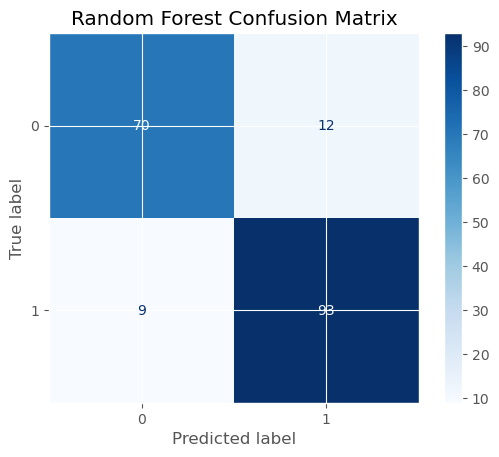

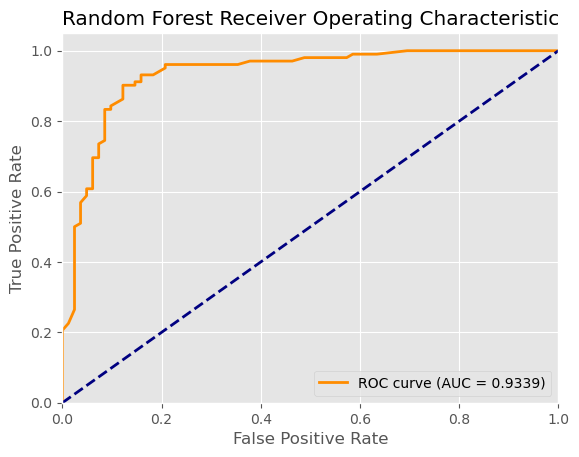


=== SVM ===
Accuracy: 0.9022
Precision: 0.8962
Recall: 0.9314
F1 Score: 0.9135
F2 Score: 0.9241
ROC AUC: 0.9449

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.87      0.89        82
           1       0.90      0.93      0.91       102

    accuracy                           0.90       184
   macro avg       0.90      0.90      0.90       184
weighted avg       0.90      0.90      0.90       184



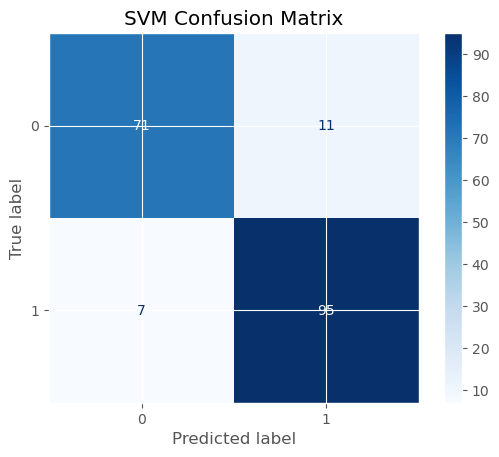

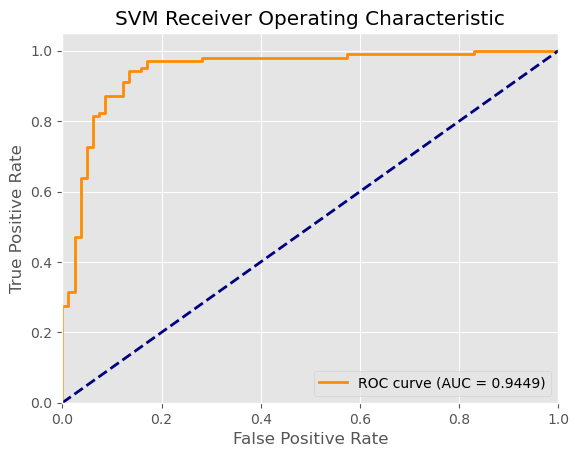


=== ANN ===
Accuracy: 0.8641
Precision: 0.8889
Recall: 0.8627
F1 Score: 0.8756
F2 Score: 0.8679
ROC AUC: 0.9083

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.87      0.85        82
           1       0.89      0.86      0.88       102

    accuracy                           0.86       184
   macro avg       0.86      0.86      0.86       184
weighted avg       0.87      0.86      0.86       184



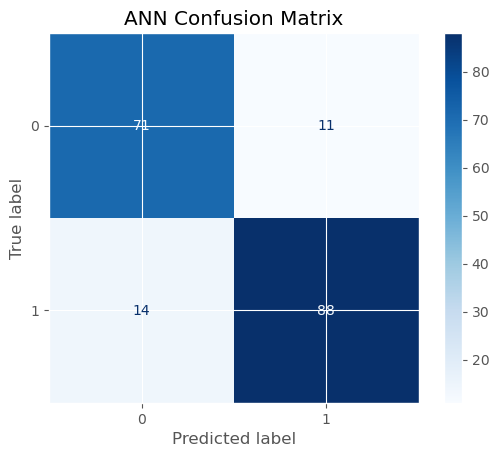

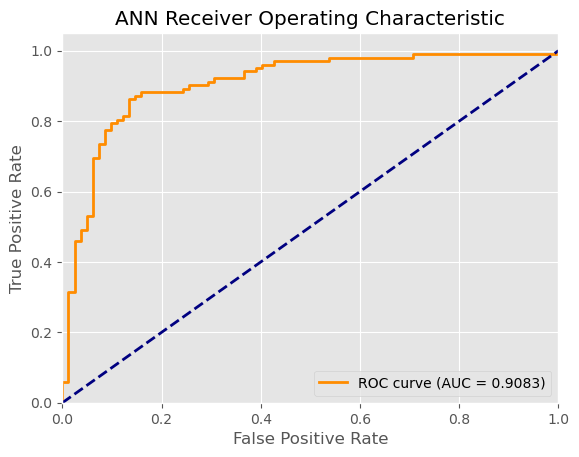

In [49]:
# List to store the evaluation results of each model
results = []

# Loop through each trained model in the dictionary
for name, model in trained_models.items():
    
    # Predict the class labels on the test set
    y_pred = model.predict(X_test_prep)
    
    # Predict the probabilities for positive class (used for ROC AUC)
    if hasattr(model, "predict_proba"):
        # Most models use predict_proba to get class probabilities
        y_proba = model.predict_proba(X_test_prep)[:, 1]
    else:
        # Some models (like SVM) use decision_function instead
        y_proba = model.decision_function(X_test_prep)
    
    # Calculate evaluation metrics
    acc = accuracy_score(y_test, y_pred)                 # Accuracy
    prec = precision_score(y_test, y_pred)               # Precision
    rec = recall_score(y_test, y_pred)                   # Recall
    f1 = f1_score(y_test, y_pred)                        # F1 Score
    f2 = fbeta_score(y_test, y_pred, beta=2)             # F2 Score (recall-focused)
    roc_auc = roc_auc_score(y_test, y_proba)             # ROC AUC Score

    # Save results to list for comparison later
    results.append({
        'Model': name, 
        'Accuracy': round(acc, 4),  
        'Precision': round(prec, 4),  
        'Recall': round(rec, 4),  
        'F1 Score': round(f1, 4),
        'F2 Score': round(f2, 4),
        'ROC AUC': round(roc_auc, 4)
    })

    # Print all metrics for this model
    print(f"\n=== {name} ===")  
    print(f"Accuracy: {acc:.4f}") 
    print(f"Precision: {prec:.4f}")  
    print(f"Recall: {rec:.4f}")  
    print(f"F1 Score: {f1:.4f}")
    print(f"F2 Score: {f2:.4f}")
    print(f"ROC AUC: {roc_auc:.4f}")

    # Show detailed classification report (includes support, etc.)
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred)) 

    # Show confusion matrix as a plot
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap='Blues')
    plt.title(f"{name} Confusion Matrix") 
    plt.show()

    # Plot ROC curve to visualize how well the model separates the classes.
    # The higher the curve and AUC score, the better the model is at distinguishing positives vs. negatives.
    fpr, tpr, _ = roc_curve(y_test, y_proba)  # False Positive Rate & True Positive Rate
    roc_auc = auc(fpr, tpr)  # Area Under Curve
    
    plt.figure()
    plt.plot(fpr, tpr, color='darkorange', lw=2, 
             label=f'ROC curve (AUC = {roc_auc:.4f})')
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')  # Diagonal line
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(f'{name} Receiver Operating Characteristic')
    plt.legend(loc="lower right")
    plt.show()

<a id="1"></a>
# <p style="padding:10px;background-color:#CADCFC;margin:0;color:#00246B;font-family:newtimeroman;font-size:150%;text-align:center;overflow:hidden;font-weight:500">Compare and Select the Best Model</p>

In this section, we compare the performance of all trained classification models based on evaluation metrics including Accuracy, Precision, Recall, F1 Score, F2 Score, and ROC AUC. We also select the best model using a Composite Evaluation Metric (CEM), calculated as 50% Recall + 30% F2 Score + 20% ROC AUC.

## Display the Model Comparison Table

In [53]:
# Convert the results list into a pandas DataFrame for easy handling and visualization
results_df = pd.DataFrame(results)

print("\n📊 Model Comparison Table:")

# Display the table with the 'Model' column as the index and highlight the maximum value in each column
# The 'style.highlight_max(axis=0)' will highlight the highest values in each column (row-wise)
display(results_df.set_index('Model').style.highlight_max(axis=0))


📊 Model Comparison Table:


,Accuracy,Precision,Recall,F1 Score,F2 Score,ROC AUC
Model,,,,,,
Random Forest,0.885900,0.885700,0.911800,0.898600,0.906400,0.933900
SVM,0.902200,0.896200,0.931400,0.913500,0.924100,0.944900
ANN,0.864100,0.888900,0.862700,0.875600,0.867900,0.908300


## Bar Graph Visualization of Model Performance

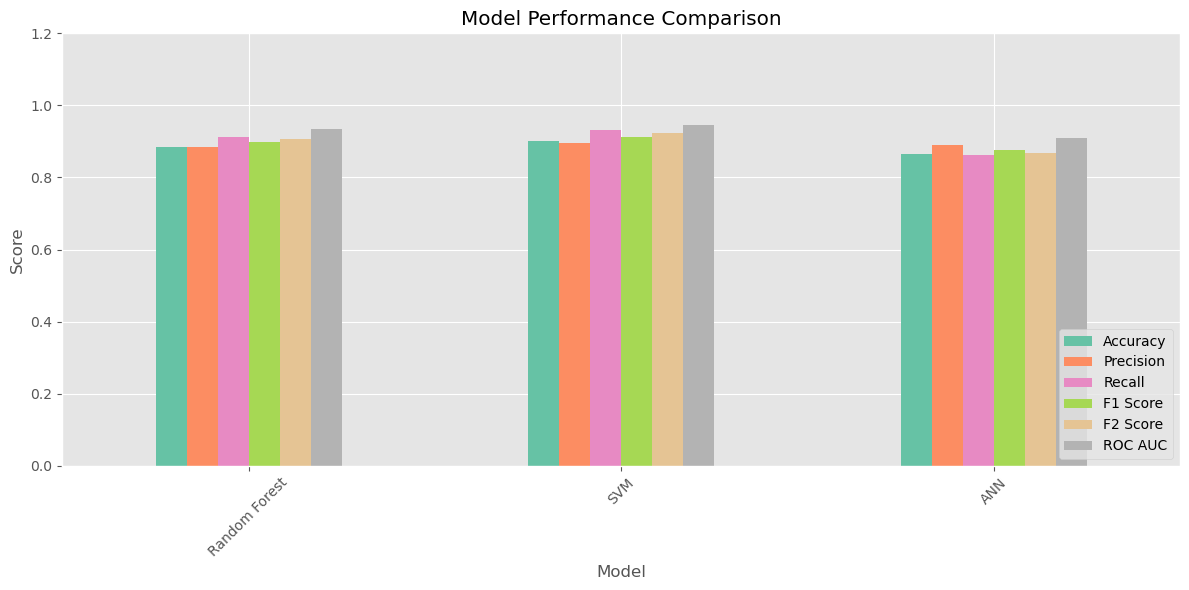

In [55]:
# Define the metrics to visualize: 'Accuracy', 'Precision', 'Recall', 'F1 Score', 'F2 Score', 'ROC AUC'
metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'F2 Score', 'ROC AUC']

# Select only the relevant metrics columns from the DataFrame
results_df_plot = results_df.set_index('Model')[metrics]

# Create a bar plot to compare the models' performance across different metrics
ax = results_df_plot.plot(kind='bar', figsize=(12, 6), colormap='Set2')

# Title and labels for the plot
plt.title("Model Performance Comparison")  # Set the title for the graph
plt.ylabel("Score")  # Label for the Y-axis, representing the performance score (0 to 1)
plt.ylim(0, 1.2)  # Set the Y-axis limits to range from 0 to 1 (with a small buffer above 1 for better visualization)

# Rotate the X-axis labels to make them readable
plt.xticks(rotation=45)

# Add the legend to the plot, specifying where to position it (bottom right)
plt.legend(loc='lower right')

# Display gridlines on the graph for easier visualization
plt.grid(True)

# Ensure everything fits in the layout without overlap
plt.tight_layout()

# Display the plot
plt.show()

## Best Model Highlighted by Composite Evaluation Metric (CEM)

This section highlights the best heart disease prediction model based on a Composite Evaluation Metric (CEM) that prioritizes Recall, F2 Score, and ROC AUC to reflect clinical importance. <br>

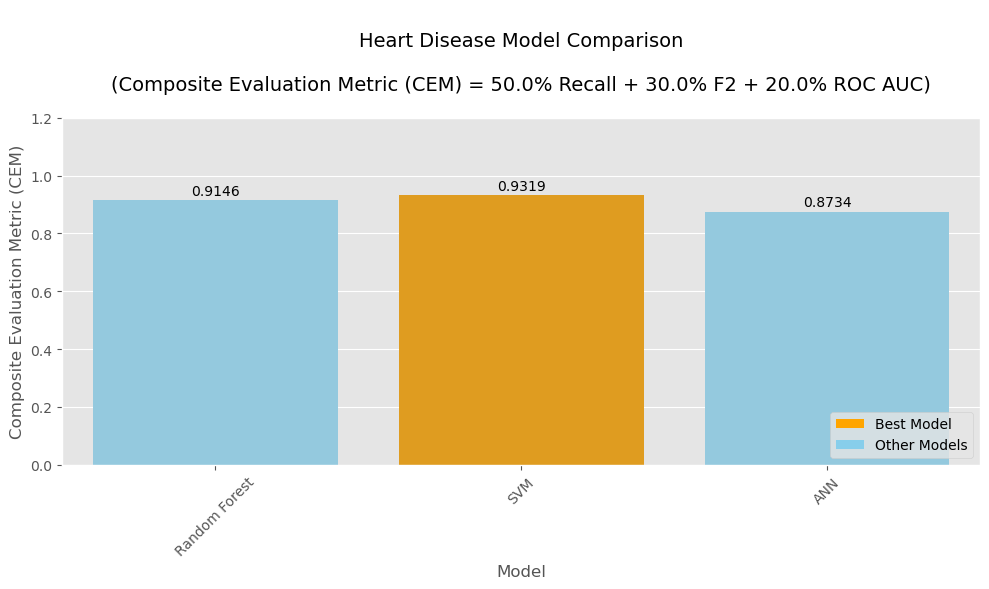

In [58]:
# Calculate composite score using weights
weights = {
    'Recall': 0.5,
    'F2 Score': 0.3, 
    'ROC AUC': 0.2
}

# Add CEM to DataFrame
results_df['CEM'] = (
    results_df['Recall'] * weights['Recall'] +
    results_df['F2 Score'] * weights['F2 Score'] +
    results_df['ROC AUC'] * weights['ROC AUC']
)

# Find the best model based on CEM
best_model_name = results_df.loc[results_df['CEM'].idxmax(), 'Model']
best_model = trained_models[best_model_name] 

# Create colors list highlighting the best model
colors = ['orange' if model == best_model_name else 'skyblue' for model in results_df['Model']]

# Plot using your original style
plt.figure(figsize=(10, 6))
sns.barplot(
    x='Model',
    y='CEM',
    data=results_df,
    palette=colors
)

# Add title with weight explanation
plt.title(f"\nHeart Disease Model Comparison\n\n(Composite Evaluation Metric (CEM) = {weights['Recall']*100}% Recall + {weights['F2 Score']*100}% F2 + {weights['ROC AUC']*100}% ROC AUC)", 
         fontsize=14, pad=20)
plt.ylabel("Composite Evaluation Metric (CEM)")
plt.ylim(0, 1.2)

# Add value labels
for i, v in enumerate(results_df['CEM']):
    plt.text(i, v + 0.02, f"{v:.4f}", ha='center', fontsize=10)

# Rotate the X-axis labels to make them readable
plt.xticks(rotation=45)

# Add legend explaining colors
plt.legend(handles=[
    plt.Rectangle((0,0),1,1,fc='orange', edgecolor='none'), 
    plt.Rectangle((0,0),1,1,fc='skyblue', edgecolor='none')
], labels=['Best Model', 'Other Models'], loc='lower right')

plt.tight_layout()
plt.show()

<a id="1"></a>
# <p style="padding:10px;background-color:#CADCFC;margin:0;color:#00246B;font-family:newtimeroman;font-size:150%;text-align:center;overflow:hidden;font-weight:500">Working Prototype with Web UI</p>

This section presents a functional prototype of the system integrated with a basic web-based user interface. The prototype demonstrates the core features and interactions of the application, allowing users to simulate real usage scenarios.

## Save Trained Model & Preprocessor

In [62]:
import joblib

# Save the best model and preprocessor using joblib
joblib.dump(best_model, 'heart_model.pkl')  # Save the best model object
joblib.dump(preprocessor, 'preprocessor.pkl')  # Save the preprocessor (needed for future data transformations)

['preprocessor.pkl']

## Open Terminal and Install Libraries
pip install flask pandas scikit-learn joblib

## Run the app
cd HeartDiseasePrediction <br>
python app.py

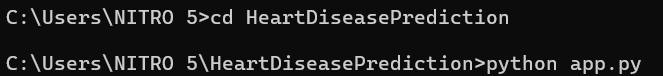

Launch the Web Application

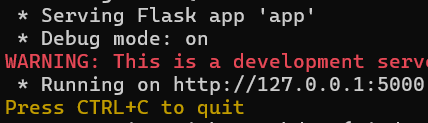

## Sample Output 1 : Low Chance of Heart Disease

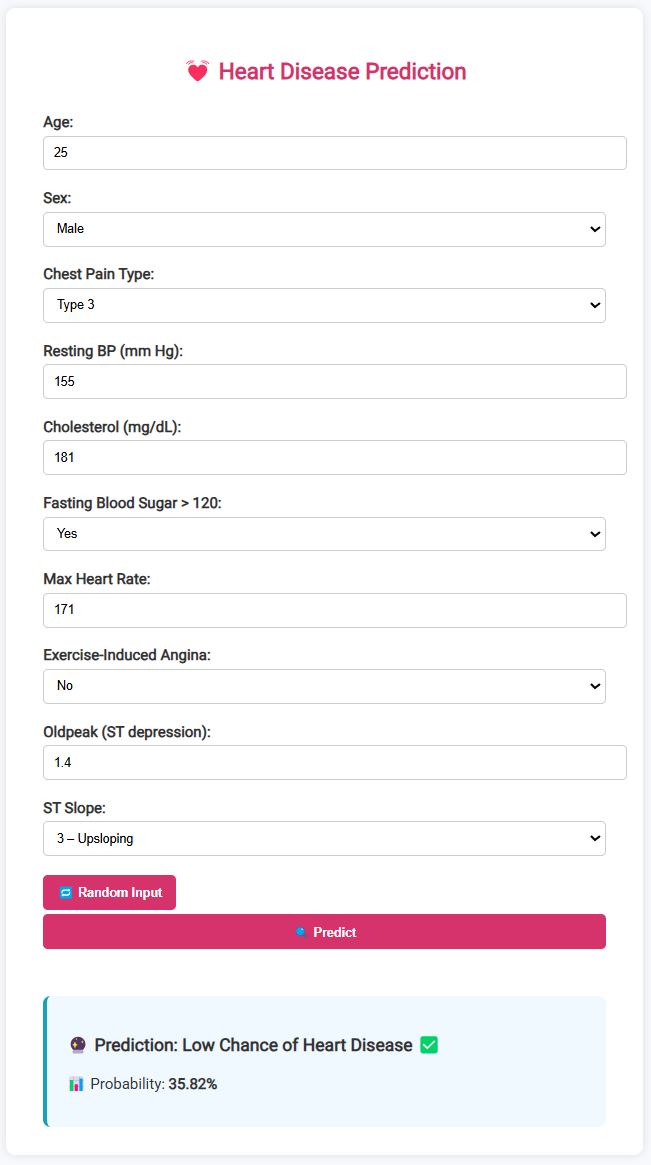

## Sample Output 2 : High Chance of Heart Disease

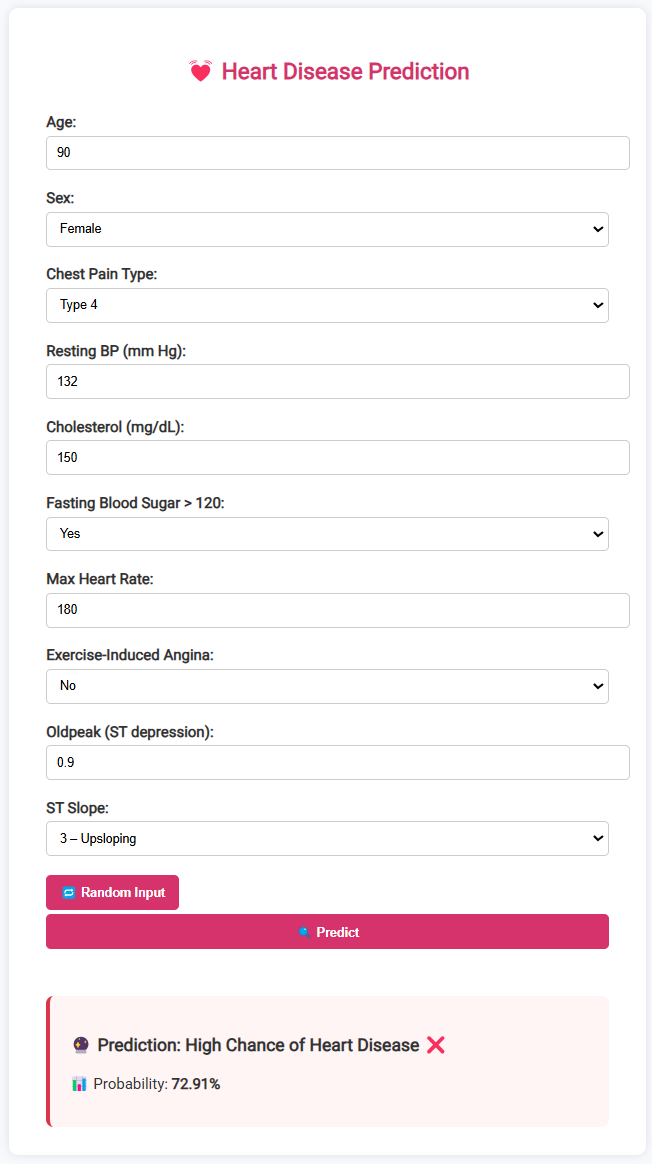